Датасет: WM-811K (карты дефектности кремниевых пластин).
Команда: инфохимики - Демина Александра, ИСУ 504844, Козлова Дарья ИСУ:504686
дизайнеры - 

Случайная велечина 1 (n_center) - дефекты в центральной зоне вафли

In [10]:
import pandas as pd

df = pd.read_parquet("../wm811k_features.parquet")
x = df["n_center"]
N = len(x)

print("пластин:", N, "| dieSize:", df["dieSize"].iloc[0])
print("среднее:", x.mean(), "| дисперсия:", x.var(ddof=1))
print("доля нулей:", (x == 0).mean(), "| max:", x.max())

пластин: 15881 | dieSize: 516.0
среднее: 22.964800705245263 | дисперсия: 37.41179619611033
доля нулей: 0.0 | max: 58


### Описание случайной величины

`n_center` это число бракованных кристаллов (чипов) в центральной зоне пластины. Кристаллами здесь называются отдельные чипы, на которые делится пластина; чип считается дефектным, если не прошел проверку контроля качества. В процессе химического осаждения на пластине растут тонкие слои (например, нитрида кремния), и из-за различных причин, таких как неравномерная подача газа, сбой цикла осаждения или неравномерный нагрев, часть чипов оказывается бракованной. Центральная зона определяется по нормированному радиусу: $r < 0.5$, где $r$ это расстояние от центра пластины до чипа, деленное на максимальное такое расстояние.

Мы считаем эту величину `n_center` случайной, потому что дефекты возникают из-за вышеописанных причин (или их совокупности), при этом все пластины (мы предположим и потом докажем, так ли это: деффектность не зависит от положения в лодочке реактора),обработанны в одинаковых условиях, число бракованных чипов при этом различается (например, внутри одной лодочки на 6 вафель(пластин) от 0 до 6). Значение также нельзя вычислить по формуле из параметров процесса или смоделировав процесс в специальном ПО. 

Мы будем рассматривать пластины одного размера: `dieSize` = 516, всего получилось 15881 пластин. Для начала предположим, что распределение случайной велечины будет распределением Пуассона. 

### EDA & Distribution 

count    15881.000000
mean        22.964801
std          6.116518
min          5.000000
25%         19.000000
50%         23.000000
75%         27.000000
max         58.000000
Name: n_center, dtype: float64
асимметрия: 0.4436329678497521 эксцесс: 0.46088267833752194
дисперсия/среднее: 1.6290930052602333


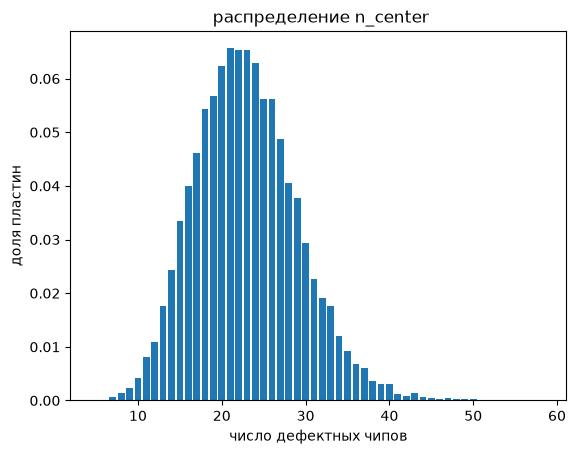

In [11]:
##EDA
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

#df.info()
#display(df.describe())

#numericals = df.select_dtypes(include=np.number).drop(columns="id", errors="ignore")

#for column in numericals.columns:
#    plt.figure(figsize=(7, 5))
#    sns.histplot(data=df, x=column, kde=True)
#    plt.show()

xv = x.to_numpy()
print(x.describe())
print("асимметрия:", stats.skew(xv), "эксцесс:", stats.kurtosis(xv))
print("дисперсия/среднее:", x.var(ddof=1) / x.mean())

vals, cnt = np.unique(xv, return_counts=True)
plt.bar(vals, cnt / N)
plt.xlabel("число дефектных чипов")
plt.ylabel("доля пластин")
plt.title(" распределение n_center")
plt.show()



Значения `n_center` лежат от 5 до 58, в данных нет пластин с нулевым значением, предположим, что пластину вообще без дефектов (на всей площади) изготовить невозможно.
 Среднее равно 22.96, дисперсия 37.41, то есть дисперсия примерно в 1.6 раза больше среднего, значит это не распределение Пуассона, для которого это отношение было бы равно 1.5.  Асимметрия 0.4436329678497521, эксцесс 0.46088267833752194. 

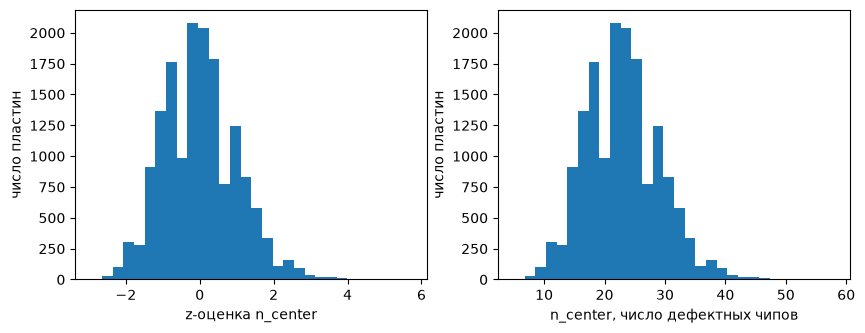

среднее z: -3.1498147848064386e-16 | std z: 1.0


In [12]:
z = (x - x.mean()) / x.std(ddof=1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(z, bins=30)
ax[0].set_xlabel("z-оценка n_center")
ax[0].set_ylabel("число пластин")
ax[1].hist(x, bins=30)
ax[1].set_xlabel("n_center, число дефектных чипов")
ax[1].set_ylabel("число пластин")
plt.show()

print("среднее z:", z.mean(), "| std z:", z.std(ddof=1))

Мы привели величину к стандартизованному виду $z = (x - \bar{x})/s$: у $z$ среднее 0 и стандартное отклонение 1. Это убирает единицы измерения и делает величину сопоставимой с другими, а также удобно для сравнения с нормальным распределением. Форма распределения при этом не меняется: график $z$ повторяет гистограмму $n\_center$ с другой шкалой.

In [13]:
mean, var = x.mean(), x.var(ddof=1)
D = (N - 1) * var / mean
p_over = stats.chi2.sf(D, N - 1)
print(f"var/mean = {var/mean:.3f}, статистика = {D:.1f}, p = {p_over:.3g}")

var/mean = 1.629, статистика = 25870.0, p = 0


Для пуассоновской величины дисперсия равна среднему. Мы проверили гипотезу $H_0$: $\mathrm{Var}=\mathrm{E}$ статистикой $D=(N-1)s^2/\bar{x}$, которая при $H_0$ распределена как $\chi^2_{N-1}$. Получили $D=⟨значение⟩$, $p=⟨значение⟩$, поэтому $H_0$ ⟨отвергаем / не отвергаем⟩. Отношение дисперсии к среднему 1.63 говорит о перерассеянии, допустим, что наше предположение про независимость дефектности от места нахождения вафли неверное, и положение пластины в лодочке; положение лодочки все же влияет на дефекты

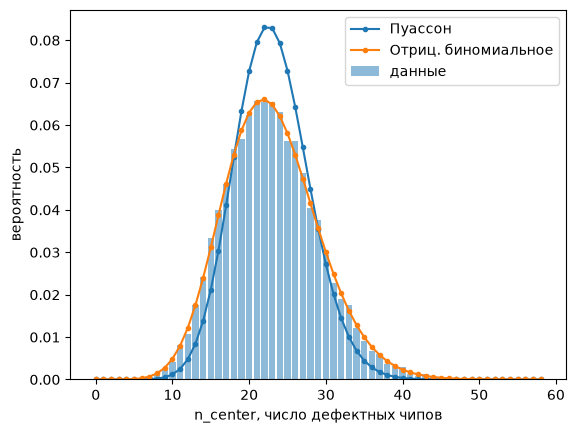

In [14]:
pois = stats.poisson(mean)
p_nb = mean / var
r_nb = mean * p_nb / (1 - p_nb)
nb = stats.nbinom(r_nb, p_nb)
fits = {"Пуассон": (pois, 1), "Отриц. биномиальное": (nb, 2)}

kk = np.arange(0, int(xv.max()) + 1)
emp = np.bincount(xv.astype(int), minlength=len(kk)) / N
plt.bar(kk, emp, alpha=0.5, label="данные")
for name, (dist, _) in fits.items():
    plt.plot(kk, dist.pmf(kk), "o-", markersize=3, label=name)
plt.xlabel("n_center, число дефектных чипов")
plt.ylabel("вероятность")
plt.legend()
plt.show()

In [15]:
def gof_chi2(x, dist, n_params, min_exp=5):
    xi = x.astype(int)
    kmax = int(xi.max())
    ks = np.arange(kmax + 1)

    observed = list(np.bincount(xi, minlength=kmax + 1).astype(float))
    expected = list(len(xi) * dist.pmf(ks))
    expected[-1] += len(xi) * dist.sf(kmax)

    while len(expected) > 2 and expected[-1] < min_exp:
        e_last, o_last = expected.pop(), observed.pop()
        expected[-1] += e_last
        observed[-1] += o_last

    while len(expected) > 2 and expected[0] < min_exp:
        e_first, o_first = expected.pop(0), observed.pop(0)
        expected[0] += e_first
        observed[0] += o_first

    chi2, p = stats.chisquare(observed, expected, ddof=n_params)
    return chi2, p, len(observed)


for name, (dist, npar) in fits.items():
    chi2, p, bins = gof_chi2(xv, dist, npar)
    print(f"{name}: chi2 = {chi2:.1f}, ячеек = {bins}, p = {p:.3g}")

Пуассон: chi2 = 3765.5, ячеек = 33, p = 0
Отриц. биномиальное: chi2 = 62.9, ячеек = 43, p = 0.0118


## Independence & Estimations

,n,mean_est,sd_mean,sd_theory,var_est,sd_var
0,10,23.0624,1.9778,1.9342,37.6972,19.6465
1,20,22.9545,1.4106,1.3677,37.9735,13.5637
2,50,22.9827,0.8522,0.8650,37.6397,8.1621
3,100,22.9131,0.6217,0.6117,37.5320,6.0608
4,200,22.9719,0.4262,0.4325,37.4188,4.1828
5,500,22.9585,0.2736,0.2735,37.2567,2.6990
6,1000,22.9698,0.1943,0.1934,37.3923,1.9521
7,2000,22.9618,0.1313,0.1368,37.4484,1.3615
8,5000,22.9636,0.0902,0.0865,37.4038,0.8341


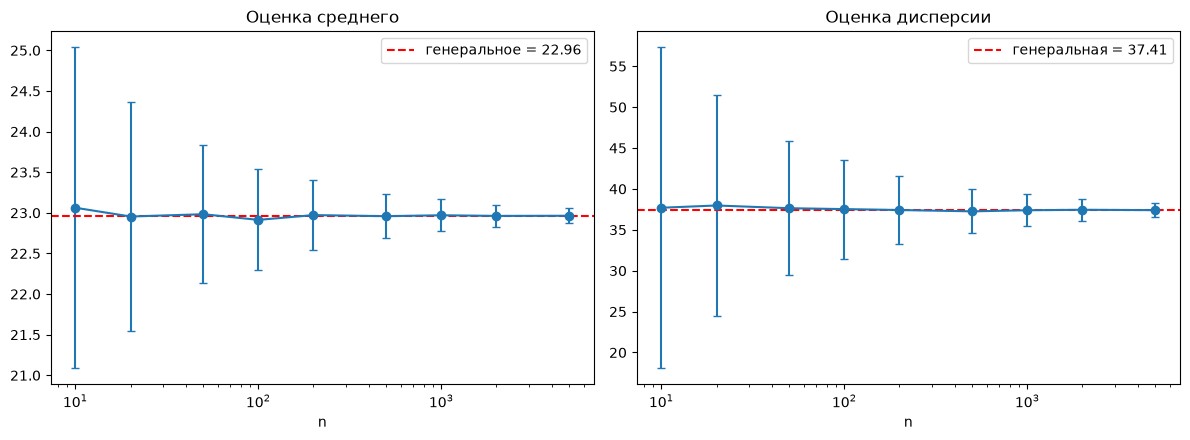

In [16]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_parquet("../wm811k_features.parquet")
x = df["n_center"]
xv = x.to_numpy()
N = len(x)
mean, var = x.mean(), x.var(ddof=1)
rng = np.random.default_rng(42)
sizes = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000]
reps = 500
res = []
for n in sizes:
    s = rng.choice(xv, size=(reps, n), replace=True)
    mm, vv = s.mean(axis=1), s.var(axis=1, ddof=1)
    res.append((n, mm.mean(), mm.std(), np.sqrt(var / n), vv.mean(), vv.std()))
cons = pd.DataFrame(res, columns=["n", "mean_est", "sd_mean", "sd_theory", "var_est", "sd_var"])
display(cons.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].errorbar(cons.n, cons.mean_est, yerr=cons.sd_mean, fmt="o-", capsize=3)
ax[0].axhline(mean, color="r", ls="--", label=f"генеральное = {mean:.2f}")
ax[0].set_xscale("log"); ax[0].set_xlabel("n"); ax[0].set_title("Оценка среднего"); ax[0].legend()
ax[1].errorbar(cons.n, cons.var_est, yerr=cons.sd_var, fmt="o-", capsize=3)
ax[1].axhline(var, color="r", ls="--", label=f"генеральная = {var:.2f}")
ax[1].set_xscale("log"); ax[1].set_xlabel("n"); ax[1].set_title("Оценка дисперсии"); ax[1].legend()
plt.tight_layout(); plt.show()

In [17]:
n, reps = 5000, 1000
rows = []
for replace in (True, False):
    ms, vs = [], []
    for _ in range(reps):
        s = rng.choice(xv, size=n, replace=replace)
        ms.append(s.mean()); vs.append(s.var(ddof=1))
    rows.append(["с возвращением" if replace else "без возвращения",
                 np.mean(ms), np.std(ms), np.mean(vs)])
rows.append(["генеральная", mean, np.nan, var])
display(pd.DataFrame(rows, columns=["схема", "среднее средних", "SD среднего", "среднее дисперсий"]).round(4))
print("теор. SD: с возвр.", np.sqrt(var / n), "| без возвр.", np.sqrt(var / n * (N - n) / (N - 1)))

,схема,среднее средних,SD среднего,среднее дисперсий
0,с возвращением,22.9698,0.0866,37.4126
1,без возвращения,22.9650,0.0723,37.4198
2,генеральная,22.9648,NaN,37.4118


теор. SD: с возвр. 0.08650063143828526 | без возвр. 0.07160254087018458


In [18]:
g = df.groupby("lotName")["n_center"]
groups = [v.values for _, v in g if len(v) >= 5]
H, p_lot = stats.kruskal(*groups)
print(f"между лотами: H = {H:.1f}, p = {p_lot:.3g}")
print("доля дисперсии между лотами:", g.transform("mean").var() / x.var())

H2, p_pos = stats.kruskal(*[v.values for _, v in df.groupby("waferIndex")["n_center"]])
print(f"по положению в лодочке: H = {H2:.1f}, p = {p_pos:.3g}")

между лотами: H = 2875.7, p = 2.75e-256
доля дисперсии между лотами: 0.17589506068842833
по положению в лодочке: H = 23.5, p = 0.492


#### Распределение Пуассона

Дискретная величина $X$ имеет распределение Пуассона с параметром $\lambda>0$, если

$$P(X=k)=\frac{\lambda^k e^{-\lambda}}{k!},\quad k=0,1,2,\dots$$

Среднее и дисперсия равны: $\mathrm{E}X=\mathrm{Var}X=\lambda$. Распределение возникает как предел биномиального при $n\to\infty$, $p\to 0$, $np=\lambda$, то есть описывает число редких независимых событий. 

#### Отрицательное биномиальное распределение

$$P(X=k)=\binom{k+r-1}{k}p^r(1-p)^k,\quad k=0,1,2,\dots$$

Среднее $\mu = r(1-p)/p$, дисперсия $\sigma^2=\mu/p>\mu$. Оно получается как смесь пуассоновских распределений, у которых интенсивность $\lambda$ сама случайна и распределена по гамма-закону. Поэтому подходит для данных, где дисперсия больше среднего. По методу моментов: $p=\bar{x}/s^2$, $r=\bar{x}p/(1-p)$.

Как мы увидели и расчитали на гистограммах выше - распределение пуассона на наши данные не ложится и гипотеза не подтверждается 

### Выводы

1. Среднее 22.96, дисперсия 37.41; дисперсия больше среднего, то есть данные перерассеяны.
2. Гипотеза о распределении Пуассона не подтверждена ($p=⟨…⟩$). ⟨Лучше подошло отрицательное биномиальное ($p=⟨…⟩$).⟩
3. Перерассеяние объясняется неоднородностью условий: уровень дефектности отличается между лотами и положениями в камере. Гипотеза о том, что положение в ложочке не влияет на деффекты также не подтвержилась
4. Разброс сужается с ростом $n$. При выборке без возвращения разброс среднего меньше, чем с возвращением.

## Lab resume

### cat_mark_table

Критерии оценивания указаны по пунктам задания. `coeff`: 1 — выполнено, 0.5 — частично, 0 — не выполнено.

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| S1-RV01-2.1 | [lab01_sprint1.ipynb#Description](notebooks/lab01_sprint1.ipynb) | 1 | `n_center`: природа величины, доказательство случайности на данных (разброс внутри лотов) |
| S1-RV01-2.3 | [lab01_sprint1.ipynb#Independence & Estimations](notebooks/lab01_sprint1.ipynb) | 0 | состоятельность оценок среднего и дисперсии: в работе |
| S1-RV01-2.4 | [lab01_sprint1.ipynb#EDA & Distribution](notebooks/lab01_sprint1.ipynb) | 0.5 | описательные статистики, гистограмма, z-score; проверка на перерассеяние |
| S1-RV01-2.5 | [lab01_sprint1.ipynb#Independence & Estimations](notebooks/lab01_sprint1.ipynb) | 0 | выборки с возвращением и без: в работе |
| S1-RV01-2.6 | [lab01_sprint1.ipynb#EDA & Distribution](notebooks/lab01_sprint1.ipynb) | 0.5 | математическая база Пуассона и отрицательного биномиального: в работе |
| S1-RV01-2.7 | [lab01_sprint1.ipynb#EDA & Distribution](notebooks/lab01_sprint1.ipynb) | 0.5 | гипотеза о Пуассоне (хи-квадрат): в работе |
| S1-RV02-2.1–2.7 | [rv02_n_edge.ipynb](notebooks/rv02_n_edge.ipynb) | 1 | `n_edge`|
| S1-RV03-2.1–2.7 | [rv03_r_def.ipynb](notebooks/rv03_r_def.ipynb) | 1 | `r_def`|
| S1-IND-2.2 | [independence_center_edge.ipynb](notebooks/independence_center_edge.ipynb) | 1 | независимость `n_center` и `n_edge`: корреляции (Пирсон 0.279, Спирмен 0.266), хи-квадрат (V = 0.131), перестановочный тест; вывод: величины зависимы, связь слабая, часть связи объясняется различиями между лотами |
| S1-EXTRA-NORM | [lab01_sprint1.ipynb#EDA & Distribution](notebooks/lab01_sprint1.ipynb) | 0.5 | нормализация (z-score) с описанием механики; для счётных данных добавить преобразование Анскомба |
| S1-EXTRA-LIT | [README.md](README.md) | 0.1 | список литературы собирается по ходу работы |
| S1-EXTRA-GIT | история коммитов репозитория | 0.5 | отдельные ветки по задачам, осмысленные сообщения коммитов, PR |
| S1-EXTRA-TABLE | [lab01_sprint1.ipynb#cat_mark_table](notebooks/lab01_sprint1.ipynb) | 1 | итоговые метрики сведены в таблицу |
| S1-EXTRA-DS | — | 0 | дополнительный датасет не брали пока что |